# Bab 8 — Algoritme Berbasis Pohon dan Metode Ensemble

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025), Bab 8
**Sumber kode:** [PacktPublishing/Scikit-Learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition) (`Chapter_8`)
**Direproduksi dan dijelaskan oleh:** Tarannia Raisha Putri — NIM 101032300231 — S1 Teknik Komputer, Telkom University

**Resep yang dibahas**

| # | Resep | Alat utama |
|---|--------|-----------|
| 8.1 | Pengantar *Decision Tree* | `DecisionTreeClassifier`, `plot_tree` |
| 8.2 | *Random Forest* dan *Bagging* | `RandomForestClassifier`, `feature_importances_` |
| 8.3 | *Gradient Boosted Machines* | `GradientBoostingClassifier` |
| 8.4 | *Tuning* Hiperparameter untuk Pohon dan Ensemble | `GridSearchCV`, heatmap skor CV |
| 8.5 | Membandingkan Metode Ensemble | `RandomForestClassifier`, `GradientBoostingClassifier`, `StackingClassifier` |
| 8.6 | Latihan Praktis Model Berbasis Pohon | *decision tree* (Wine), *forest* hasil *tuning* (Breast Cancer), *forest* vs *boosting* (Digits) |

> Nomor resep ditambahkan di sini untuk memudahkan navigasi; buku aslinya tidak menomori resep. Resep 8.6 memakai solusi resmi dari notebook *Exercise Solutions* di repositori. (Judul notebook buku untuk bab ini bertuliskan "Support Vector Machines and Kernel Methods", sebuah salah salin; isinya adalah metode berbasis pohon.)

## Gambaran Umum Bab

*Decision tree* memprediksi dengan mengajukan serangkaian pertanyaan ya/tidak tentang fitur ("apakah *petal width* ≤ 0,8 cm?") hingga mencapai daun yang berisi jawaban. Model ini intuitif, tidak memerlukan penskalaan fitur, dan menangkap efek non-linear serta interaksi secara otomatis. Kelemahannya adalah **variansi tinggi**: pohon yang tumbuh penuh menghafal data latihnya, dan perubahan kecil pada data dapat menghasilkan pohon yang sangat berbeda.

**Ensemble** mengatasi hal ini dengan menggabungkan banyak pohon. **Bagging/random forest** melatih pohon secara independen pada sampel *bootstrap* dengan subset fitur acak lalu merata-ratakannya, yang mengurangi variansi. **Boosting** melatih pohon dangkal secara berurutan, masing-masing mengoreksi kesalahan ensemble sejauh ini, yang mengurangi bias. **Stacking** melatih meta-model pada prediksi berbagai model dasar. Bab ini membangun masing-masing metode pada Iris, men-*tuning* model *gradient boosting*, membandingkan ketiga strategi ensemble, lalu menerapkannya pada Wine, Breast Cancer, dan Digits. Dalam *pipeline* ML, ini adalah tahap *pemodelan* dengan metode serbaguna terkuat untuk data tabular, dan bab ini memakai ulang alat *tuning* serta evaluasi dari Bab 4, 6, dan 7.

## Persiapan

In [1]:
# Pustaka inti yang dipakai di sepanjang bab ini
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn

# Satu seed global agar setiap eksekusi notebook menghasilkan angka yang sama.
# (Sel-sel buku tetap memakai nilai random_state masing-masing.)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Catat lingkungan persis yang menghasilkan output di bawah
print(f"Python       : {sys.version.split()[0]}")
print(f"numpy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")

Python       : 3.13.5
numpy        : 2.1.3
pandas       : 2.2.3
scikit-learn : 1.5.2
matplotlib   : 3.9.4


## Resep 8.1 — Pengantar *Decision Tree*

**Tujuan.** Melatih *classifier decision tree* pada Iris, mengevaluasinya, dan memvisualisasikan urutan pemisahan (*split*) yang dipelajari.

### Teori

**Intuisi.** *Decision tree* berulang kali membagi data menjadi dua kelompok memakai satu fitur dan satu ambang, dengan memilih pemisahan yang membuat setiap kelompok se-"murni" mungkin (didominasi satu kelas). Pemisahan terus dilakukan pada setiap kelompok hingga kelompok itu murni atau aturan penghentian berlaku. Sampel baru diklasifikasikan dengan mengikuti pertanyaan dari akar hingga daun dan mengambil kelas mayoritas sampel latih di daun tersebut.

**Matematika.** Pada simpul yang berisi sampel dengan proporsi kelas $p_1,\dots,p_K$, ketidakmurnian (*impurity*) diukur dengan **indeks Gini** atau **entropi**:
$$G=1-\sum_{k=1}^{K}p_k^2,\qquad H=-\sum_{k=1}^{K}p_k\log_2p_k.$$
Keduanya bernilai 0 untuk simpul murni dan terbesar ketika kelas tercampur merata. Untuk kandidat pemisahan $n$ sampel simpul pada fitur $j$ dengan ambang $t$ menjadi anak kiri ($x_j\le t$, $n_L$ sampel) dan anak kanan ($n_R$ sampel), **penurunan ketidakmurnian**-nya adalah
$$\Delta I = I(\text{induk})-\frac{n_L}{n}I(\text{kiri})-\frac{n_R}{n}I(\text{kanan}).$$
Algoritme CART secara rakus (*greedy*) memilih $(j,t)$ dengan $\Delta I$ terbesar di setiap simpul lalu berlanjut secara rekursif. Disebut rakus karena tidak pernah meninjau ulang pemisahan sebelumnya.

**Cara scikit-learn mengimplementasikannya.** `DecisionTreeClassifier(criterion="gini", splitter="best", max_depth=None, min_samples_split=2, min_samples_leaf=1, max_features=None, random_state=None, ccp_alpha=0.0)`.

* `fit` menumbuhkan pohon dengan CART yang dioptimalkan. Dengan nilai default, pohon tumbuh **hingga setiap daun murni**.
* Fitur diperiksa dalam urutan acak di setiap simpul, sehingga `random_state` menentukan cara memutus seri antara pemisahan yang sama baiknya.
* `predict` mengarahkan sampel ke daun, dan `predict_proba` mengembalikan proporsi kelas di daun.
* Kompleksitas dikendalikan dengan `max_depth`, `min_samples_leaf`, atau *cost-complexity pruning* (`ccp_alpha`).
* `plot_tree(..., filled=True, proportion=True)` menggambar setiap simpul dengan aturan pemisahan, ketidakmurnian, porsi sampel, dan proporsi kelasnya.

**Asumsi, kelebihan, keterbatasan.**

* Tanpa asumsi distribusi, tidak terpengaruh transformasi fitur yang monoton (tidak perlu penskalaan), menangani interaksi, dan mudah ditafsirkan.
* Pemisahan yang sejajar sumbu mengaproksimasi batas diagonal dengan "tangga". Pohon yang tumbuh penuh **overfitting** (variansi tinggi) dan tidak stabil terhadap perubahan kecil pada data.
* Gunakan pohon tunggal untuk kemudahan tafsir atau sebagai komponen dasar. Gunakan ensemble (resep berikutnya) untuk akurasi.

### Kode

In [2]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

# Pembagian 70/30 -> 105 bunga latih / 45 bunga uji (pembagian yang sama untuk setiap resep di bab ini)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [3]:
# Pohon CART yang tumbuh penuh (Gini impurity, tanpa batas kedalaman)
clf = DecisionTreeClassifier(random_state=2024)

clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

styled_df

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


In [4]:
# Ukuran pohon, kecocokan latih, dan bunga uji mana yang salah diklasifikasikan (tambahan)
dt_wrong = np.flatnonzero(clf.predict(X_test) != y_test)
print(f"kedalaman = {clf.get_depth()}, daun = {clf.get_n_leaves()}, akurasi latih = {clf.score(X_train, y_train):.3f}, akurasi uji = {accuracy:.3f}")
print("indeks uji yang salah:", dt_wrong, "| sebenarnya:", y_test[dt_wrong], "| prediksi:", clf.predict(X_test)[dt_wrong])

kedalaman = 4, daun = 5, akurasi latih = 1.000, akurasi uji = 0.867
indeks uji yang salah: [ 3 10 17 26 35 38] | sebenarnya: [2 1 2 2 1 2] | prediksi: [1 2 1 1 2 1]


**Interpretasi output.**

* Pohon mencapai akurasi uji **86,7 %** (39/45).
* Setosa sempurna (18/18). Versicolor memiliki *recall* 0.833 dan virginica *recall* 0.733, yang terlemah sejauh ini di buku untuk Iris pada pembagian ini.
* Pengecekan tambahan menunjukkan ciri klasik *overfitting*: **akurasi latih 1.000** dengan pohon berkedalaman 4 yang hanya memiliki 5 daun. Setiap bunga latih diklasifikasikan dengan benar, tetapi aturannya tidak berpindah sempurna ke data baru.
* Keenam kesalahan (indeks uji 3, 10, 17, 26, 35, 38) semuanya kekeliruan versicolor ↔ virginica: empat virginica diprediksi versicolor dan dua versicolor diprediksi virginica. Resep-resep berikutnya kembali membahas keenam bunga ini.

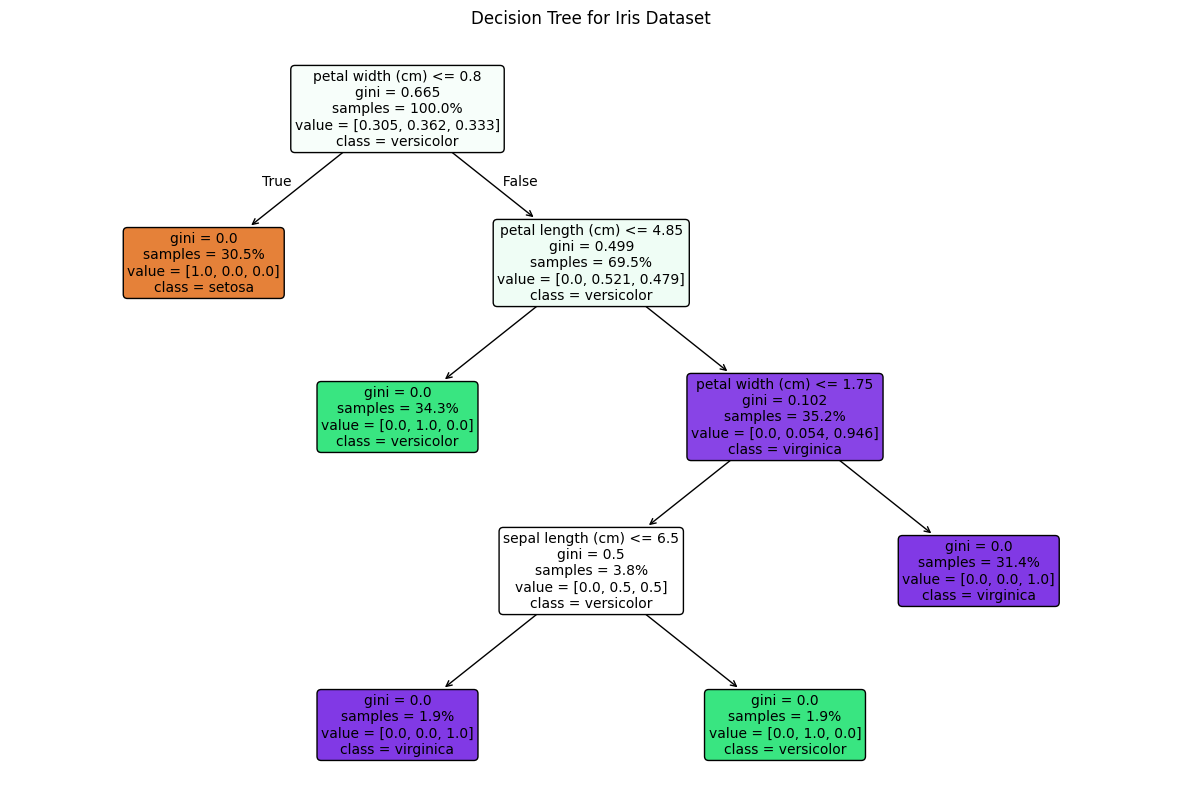

In [5]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Gambar pohon hasil fit: aturan pemisahan, Gini, porsi sampel, proporsi kelas
plt.figure(figsize=(15,10))
plot_tree(clf, feature_names=iris.feature_names, class_names=iris.target_names, filled=True, proportion=True, rounded=True, fontsize=10)
plt.title("Decision Tree for Iris Dataset")
plt.show()

**Interpretasi output.** Membaca pohon dari akarnya:

1. **Akar:** `petal width ≤ 0.8` dengan Gini **0.665**. Nilai ini sama dengan $1-(0.305^2+0.362^2+0.333^2)$ untuk proporsi kelas di akar. Cabang kiri (30,5 % sampel latih) adalah daun **setosa** yang murni: satu pertanyaan sudah memisahkan setosa sepenuhnya.
2. **Pemisahan kedua:** `petal length ≤ 4.85` mengirim 34,3 % sampel ke daun **versicolor** yang murni.
3. **Pemisahan ketiga:** `petal width ≤ 1.75` memisahkan daun **virginica** murni yang besar (31,4 %) dari simpul campuran kecil yang memuat 3,8 % sampel (4 bunga, separuh versicolor dan separuh virginica).
4. **Pemisahan terakhir:** simpul 4 bunga itu dipisah oleh `sepal length ≤ 6.5` menjadi dua daun masing-masing 1,9 % (2 bunga per daun).

Pemisahan terakhir ini persis jenis aturan yang terlalu spesifik yang diperlukan untuk mencapai akurasi latih sempurna. Aturan ini hanya didasarkan pada dua bunga di setiap sisi dan kecil kemungkinannya bergeneralisasi. Membatasi `max_depth` atau `min_samples_leaf`, atau memakai *pruning*, akan menghilangkannya. Perhatikan juga bahwa pohon memakai fitur petal untuk semua pemisahan penting, sesuai dengan *feature importance* di Resep 8.2.

### Poin Penting
* CART memilih, di setiap simpul, fitur/ambang dengan penurunan ketidakmurnian (Gini) terbesar, secara rakus dan rekursif.
* Pohon yang tumbuh penuh mem-fit data latih dengan sempurna (kedalaman 4, 5 daun) tetapi hanya mencapai 86,7 % pada data uji. Pemisahan terakhirnya bergantung pada 4 bunga latih.
* Pohon mudah dibaca: satu aturan *petal width* memisahkan setosa, dan *petal length/width* menangani sebagian besar sisanya.

## Resep 8.2 — *Random Forest* dan *Bagging*

**Tujuan.** Mengurangi variansi pohon tunggal dengan merata-ratakan 100 pohon acak (*random forest*), mengevaluasinya pada pembagian Iris yang sama, dan memeriksa fitur mana yang diandalkan *forest*.

### Teori

**Intuisi.** Satu pohon yang dalam adalah model berbias rendah dan bervariansi tinggi, dan sampel latih yang berbeda akan menghasilkan pohon yang cukup berbeda. Merata-ratakan banyak pohon seperti itu meniadakan sebagian besar variabilitas tersebut, *asalkan pohon-pohon itu membuat kesalahan yang berbeda*. *Random forest* mendorong keragaman dengan dua cara: setiap pohon melihat **sampel bootstrap** yang berbeda (mengambil $n$ baris dengan pengembalian, yang setiap kalinya meninggalkan sekitar 37 % baris), dan setiap pemisahan hanya mempertimbangkan **subset fitur acak**.

**Matematika.** Jika $B$ pohon masing-masing memiliki variansi prediksi $\sigma^2$ dan korelasi berpasangan $\rho$, variansi rata-ratanya adalah
$$\mathrm{Var}\Big(\frac1B\sum_{b=1}^{B}T_b(\mathbf{x})\Big)=\rho\,\sigma^2+\frac{1-\rho}{B}\,\sigma^2.$$
Menambah pohon mengecilkan suku kedua menuju 0, dan menurunkan korelasi antarpohon (subset fitur acak) mengecilkan suku pertama. Untuk klasifikasi, scikit-learn merata-ratakan estimasi peluang kelas dari setiap pohon, $\hat P(y=k\mid\mathbf{x})=\frac1B\sum_b\hat P_b(y=k\mid\mathbf{x})$, lalu memprediksi arg max-nya (*soft vote*, bukan suara mayoritas keras). **Mean Decrease in Impurity (MDI) importance** fitur $j$ menjumlahkan penurunan ketidakmurnian berbobot $\frac{n_t}{n}\Delta I_t$ atas semua simpul $t$ yang memisah pada $j$, merata-ratakannya atas semua pohon, lalu menormalisasinya agar total semua *importance* sama dengan 1.

**Cara scikit-learn mengimplementasikannya.** `RandomForestClassifier(n_estimators=100, criterion="gini", max_depth=None, max_features="sqrt", bootstrap=True, oob_score=False, n_jobs=None, random_state=None)`.

* Setiap pohon adalah `DecisionTreeClassifier` yang tumbuh penuh dan dilatih pada sampel *bootstrap*, dengan mempertimbangkan $\lfloor\sqrt{p}\rfloor$ fitur per pemisahan (2 dari 4 di sini).
* `feature_importances_` menyimpan MDI *importance*.
* `oob_score=True` mengevaluasi setiap pohon pada baris yang tidak dilihatnya, sehingga memberi estimasi validasi secara gratis.
* Pohon-pohon saling independen, sehingga `n_jobs=-1` melatihnya secara paralel.

**Asumsi, kelebihan, keterbatasan.**

* Tangguh, sedikit membutuhkan *tuning*, tanpa penskalaan, menangani banyak fitur, dan jarang *overfitting* parah ketika pohon ditambah.
* Kurang mudah ditafsirkan dibanding satu pohon, dan biaya memori/prediksi tumbuh seiring $B$.
* MDI *importance* dihitung pada data latih dan bias terhadap fitur kontinu atau berkardinalitas tinggi. *Permutation importance* (`sklearn.inspection.permutation_importance`) pada data yang disisihkan lebih dapat diandalkan.

### Kode

In [6]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [7]:
# 100 pohon ber-bootstrap dengan subsampel fitur, peluangnya dirata-ratakan
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)

rf_clf.fit(X_train, y_train)

y_pred = rf_clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

styled_df

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.833,0.833,0.833,12
2,0.867,0.867,0.867,15
accuracy,0.911,0.911,0.911,1
macro avg,0.900,0.900,0.900,45
weighted avg,0.911,0.911,0.911,45


In [8]:
# Bandingkan kesalahan forest dengan kesalahan pohon tunggal (tambahan)
rf_wrong = np.flatnonzero(y_pred != y_test)
print(f"akurasi latih = {rf_clf.score(X_train, y_train):.3f}, akurasi uji = {accuracy:.3f}")
print("forest salah pada:", rf_wrong, "| pohon tunggal salah pada:", dt_wrong)
print("kesalahan yang diperbaiki forest:", np.setdiff1d(dt_wrong, rf_wrong))

akurasi latih = 1.000, akurasi uji = 0.911
forest salah pada: [ 3 10 17 35] | pohon tunggal salah pada: [ 3 10 17 26 35 38]
kesalahan yang diperbaiki forest: [26 38]


**Interpretasi output.**

* *Forest* mencapai akurasi uji **91,1 %** (41/45), naik dari 86,7 % untuk pohon tunggal.
* Versicolor dan virginica kini sama-sama memiliki *precision* = *recall* (0.833 dan 0.867).
* Pengecekan tambahan menunjukkan *forest* masih mem-fit data latih dengan sempurna (1.000), tetapi **4 kesalahannya merupakan subset dari 6 kesalahan pohon**. Perata-rataan memperbaiki bunga uji 26 dan 38, yang salah pada pohon tunggal, tanpa menambah kesalahan baru. Inilah pengurangan variansi dalam praktik: batas hasil rata-rata *forest* lebih halus daripada batas pohon tunggal mana pun.

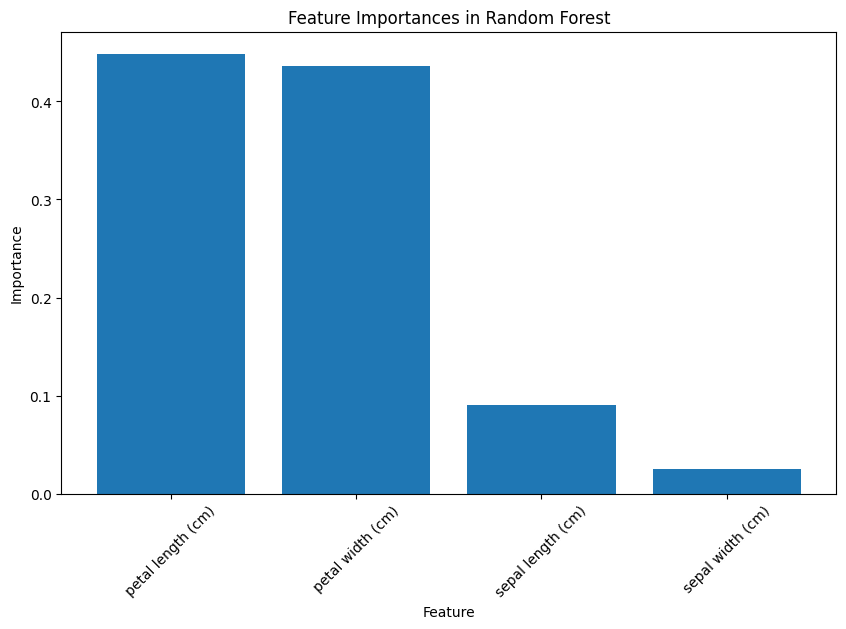

In [9]:
import matplotlib.pyplot as plt

# MDI importance, diurutkan dari yang paling hingga paling tidak penting
importances = rf_clf.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10,6))
plt.title("Feature Importances in Random Forest")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), [iris.feature_names[i] for i in indices], rotation=45)
plt.xlabel("Feature")  # (tambahan)
plt.ylabel("Importance")
plt.show()

> **Catatan:** Baris `plt.xlabel(...)` yang ditandai `# (tambahan)` tidak ada di buku. Baris ini hanya memberi label sumbu x.

In [10]:
# Nilai importance yang tepat (tambahan)
pd.Series(importances, index=iris.feature_names).sort_values(ascending=False).round(3)

petal length (cm)    0.449
petal width (cm)     0.436
sepal length (cm)    0.090
sepal width (cm)     0.025
dtype: float64

**Interpretasi output.** *Forest* hampir sepenuhnya bergantung pada petal: **petal length (0.449)** dan **petal width (0.436)** bersama-sama menyumbang sekitar 88 % dari total penurunan ketidakmurnian. *Sepal length* (0.090) dan terutama *sepal width* (0.025) hanya berkontribusi sedikit. Hal ini sesuai dengan pohon tunggal, yang hanya memisah pada fitur petal kecuali pemisahan terakhirnya yang terlalu spesifik, serta dengan *pairplot* di Bab 6, tempat petal memisahkan spesies jauh lebih baik daripada sepal. Karena *petal length* dan *width* sangat berkorelasi, *forest* membagi kreditnya di antara keduanya. Pada MDI, *importance* terbagi di antara fitur-fitur yang berkorelasi.

### Poin Penting
* *Random forest* merata-ratakan pohon ber-*bootstrap* dengan subsampel fitur, yang mengurangi variansi sesuai $\rho\sigma^2+(1-\rho)\sigma^2/B$.
* Akurasi uji naik dari 86,7 % (pohon tunggal) menjadi 91,1 %, memperbaiki 2 dari 6 kesalahan pohon tanpa menambah kesalahan baru.
* MDI *importance*: *petal length* 0.449, *petal width* 0.436, *sepal length* 0.090, *sepal width* 0.025.

## Resep 8.3 — *Gradient Boosted Machines*

**Tujuan.** Membangun *classifier gradient boosting*, yaitu ensemble pohon dangkal yang ditambahkan satu per satu untuk mengoreksi kesalahan saat itu, lalu mengevaluasinya pada pembagian Iris.

### Teori

**Intuisi.** Alih-alih merata-ratakan pohon yang independen, *boosting* membangun **tim yang belajar dari kesalahannya**. Mulai dari prediksi sederhana (prior kelas). Fit sebuah pohon kecil pada kesalahan saat ini, tambahkan versi yang diperkecil dari pohon itu ke model, hitung ulang kesalahannya, lalu ulangi. Setiap pohon lemah jika berdiri sendiri, tetapi jumlahnya menjadi sangat akurat. Karena setiap pohon menyasar apa yang masih salah dari ensemble, *boosting* terutama **mengurangi bias**.

**Matematika.** *Gradient boosting* membangun model aditif
$$F_M(\mathbf{x})=F_0(\mathbf{x})+\nu\sum_{m=1}^{M}h_m(\mathbf{x}),$$
dengan $\nu\in(0,1]$ adalah **learning rate** (*shrinkage*). Pada langkah $m$, algoritme menghitung **pseudo-residual**, yaitu gradien negatif *loss* $L$ terhadap prediksi saat ini,
$$r_{im}=-\left.\frac{\partial L\big(y_i,F(\mathbf{x}_i)\big)}{\partial F(\mathbf{x}_i)}\right|_{F=F_{m-1}},$$
mem-fit pohon regresi $h_m$ pada $\{(\mathbf{x}_i,r_{im})\}$, menetapkan nilai daunnya dengan langkah Newton, lalu memperbarui $F_m=F_{m-1}+\nu h_m$. Ini adalah *gradient descent* di ruang fungsi. Untuk log-loss $K$ kelas, ada satu skor $F^{(k)}$ per kelas, peluang diperoleh dari softmax, pseudo-residualnya $\mathbb{1}[y_i=k]-p_k(\mathbf{x}_i)$, dan **$K$ pohon di-fit per iterasi**. $\nu$ yang lebih kecil membutuhkan lebih banyak pohon tetapi biasanya bergeneralisasi lebih baik (*shrinkage* berperan sebagai regularisasi).

**Cara scikit-learn mengimplementasikannya.** `GradientBoostingClassifier(loss="log_loss", learning_rate=0.1, n_estimators=100, subsample=1.0, max_depth=3, criterion="friedman_mse", n_iter_no_change=None, random_state=None)`.

* Pohon di-fit secara berurutan (tidak ada paralelisme antarpohon). `train_score_` mencatat *loss* latih setelah setiap iterasi.
* `subsample<1` menghasilkan *stochastic gradient boosting*. `n_iter_no_change` bersama `validation_fraction` mengaktifkan *early stopping*.
* Resep ini memakai `n_estimators=1000, learning_rate=0.2`, sehingga untuk 3 kelas model berisi 3.000 pohon regresi berkedalaman 3.
* `HistGradientBoostingClassifier` adalah implementasi berbasis histogram yang jauh lebih cepat untuk dataset besar.

**Asumsi, kelebihan, keterbatasan.**

* Sering menjadi keluarga model paling akurat untuk data tabular, dan fleksibel melalui pilihan fungsi *loss*.
* Sensitif terhadap hiperparameter (`learning_rate` × `n_estimators`, `max_depth`). Tanpa *early stopping* atau *shrinkage*, model bisa *overfitting* pada data berisik.
* Pelatihan berurutan lebih lambat daripada *random forest*, dan modelnya kurang mudah ditafsirkan dibanding satu pohon.

### Kode

In [11]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [12]:
# 1.000 iterasi boosting dengan shrinkage 0.2 (3 pohon berkedalaman 3 per iterasi untuk 3 kelas)
gbm_clf = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.2, random_state=2024)

gbm_clf.fit(X_train, y_train)

y_pred = gbm_clf.predict(X_test)

report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

styled_df = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)
styled_df

,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


In [13]:
# Loss latih selama iterasi boosting dan bunga yang salah diklasifikasikan (tambahan)
print("log-loss latih setelah 1 / 10 / 100 / 1000 iterasi:",
      [f"{gbm_clf.train_score_[i]:.2e}" for i in (0, 9, 99, 999)])
print("pohon regresi dalam model:", gbm_clf.estimators_.size)
print("salah klasifikasi:", np.flatnonzero(y_pred != y_test), "| pohon tunggal:", dt_wrong)

log-loss latih setelah 1 / 10 / 100 / 1000 iterasi: ['7.43e-01', '5.72e-02', '1.65e-08', '1.65e-08']
pohon regresi dalam model: 3000
salah klasifikasi: [ 3 10 17 26 35 38] | pohon tunggal: [ 3 10 17 26 35 38]


**Interpretasi output.**

* *Gradient boosting* mencapai **86,7 %**, persis skor *decision tree* tunggal, dengan **angka per kelas yang identik** (versicolor 0.714/0.833, virginica 0.846/0.733).
* Pengecekan tambahan menunjukkan alasannya. *Loss* latih anjlok dari 0,74 setelah iterasi pertama menjadi sekitar $10^{-8}$ pada iterasi ke-100 dan tetap di sana, sehingga 900 iterasi sisanya (2.700 dari 3.000 pohon model) praktis tidak menambah apa pun.
* Model telah menghafal data latih, dan salah mengklasifikasikan **enam bunga uji yang sama** dengan pohon tunggal.
* Pada dataset kecil yang hampir terpisah sempurna, pengurangan bias oleh *boosting* tidak punya apa-apa lagi untuk diperbaiki. Kesalahannya berasal dari bunga yang ukurannya memang mirip spesies lain.

### Poin Penting
* *Gradient boosting* mem-fit setiap pohon baru pada pseudo-residual (gradien negatif) *loss* dan menambahkannya dengan *shrinkage* $\nu$.
* Di sini 1.000 iterasi jauh melebihi kebutuhan: *loss* latih mencapai sekitar $10^{-8}$ pada iterasi ke-100.
* Akurasi uji sama dengan pohon tunggal (86,7 %) dengan enam kesalahan yang persis sama. Kapasitas tambahan tidak dapat memperbaiki sampel yang berada di sisi yang salah dari daerah tumpang tindih kelas.

## Resep 8.4 — *Tuning* Hiperparameter untuk Pohon dan Ensemble

**Tujuan.** Men-*tuning* jumlah pohon, kedalaman pohon, dan *learning rate* *classifier gradient boosting* dengan *grid search* ber-*cross-validation*, lalu memvisualisasikan akurasi CV sebagai heatmap.

### Teori

**Intuisi.** Pada *boosting*, kenop-kenop utama saling berinteraksi. `n_estimators` × `learning_rate` menentukan seberapa jauh model bergerak secara keseluruhan (banyak langkah kecil atau sedikit langkah besar), dan `max_depth` menentukan seberapa kompleks setiap langkah (kedalaman $d$ memungkinkan interaksi hingga $d$ fitur). *Grid search* dengan *cross-validation* menjelajahi kombinasinya dan mempertahankan yang terbaik (Resep 4.3).

**Matematika.** Gridnya adalah $\{50,100,150\}\times\{3,4,5\}\times\{0.01,0.1,0.2\}$, menghasilkan 27 pengaturan yang masing-masing dinilai dengan rata-rata akurasi CV 5-fold, total 135 kali fitting model. Heatmap memakai `pivot_table`, yang agregasi default-nya adalah **rata-rata**. Karena itu setiap sel menampilkan, untuk satu pasangan (`max_depth`, `n_estimators`), akurasi CV yang **dirata-ratakan atas ketiga learning rate**:
$$\text{sel}(d,M)=\frac13\sum_{\nu\in\{0.01,0.1,0.2\}}\mathrm{CV}(d,M,\nu).$$

**Cara scikit-learn mengimplementasikannya.** `GridSearchCV(GradientBoostingClassifier(random_state=2024), param_grid, cv=5, scoring="accuracy")`. `cv_results_` menyimpan satu baris per pengaturan, dengan parameter di kolom `param_*` dan skor di `mean_test_score`. `best_estimator_` di-fit ulang pada seluruh data latih. Pengaturan yang seri berbagi peringkat 1, dan `best_params_` melaporkan yang pertama menurut urutan grid.

**Asumsi, kelebihan, keterbatasan.**

* Grid menyeluruh tumbuh secara perkalian. Untuk *boosting*, *early stopping* (`n_iter_no_change`) atau *randomized search* adalah cara yang lebih murah untuk menetapkan `n_estimators`.
* Dengan 105 sampel latih, setiap *fold* CV berisi 21 bunga, sehingga akurasi CV bergerak dalam langkah sekitar 0,0095 (satu bunga dalam lima *fold*) dan banyak pengaturan yang seri.

### Kode

In [14]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [15]:
# 3 x 3 x 3 = 27 konfigurasi boosting
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2]
}

grid_search = GridSearchCV(GradientBoostingClassifier(random_state=2024),
                           param_grid,
                           cv=5,
                           scoring='accuracy')

grid_search.fit(X_train, y_train)

print(f'Best Parameters: {grid_search.best_params_}')

# best_estimator_ sudah di-fit ulang pada seluruh data latih
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)

report = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

styled_df = (report
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

styled_df

Best Parameters: {'learning_rate': 0.01, 'max_depth': 4, 'n_estimators': 50}


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.714,0.833,0.769,12
2,0.846,0.733,0.786,15
accuracy,0.867,0.867,0.867,1
macro avg,0.853,0.856,0.852,45
weighted avg,0.873,0.867,0.867,45


In [16]:
# Tabel CV lengkap per learning rate, dan berapa pengaturan yang seri di posisi pertama (tambahan)
cv_tab = pd.DataFrame(grid_search.cv_results_)
print("pengaturan yang seri di peringkat 1:", int((cv_tab["rank_test_score"] == 1).sum()), "dari", len(cv_tab),
      "| akurasi CV terbaik:", round(grid_search.best_score_, 4))
print("model hasil tuning salah pada:", np.flatnonzero(y_pred != y_test))
cv_tab.pivot_table(values="mean_test_score", index=["param_learning_rate", "param_max_depth"],
                   columns="param_n_estimators").round(4)

pengaturan yang seri di peringkat 1: 20 dari 27 | akurasi CV terbaik: 0.981
model hasil tuning salah pada: [ 3 10 17 26 35 38]


param_n_estimators                      50      100     150
param_learning_rate param_max_depth                        
0.01                3                0.9714  0.9714  0.9619
                    4                0.9810  0.9810  0.9810
                    5                0.9810  0.9810  0.9810
0.10                3                0.9714  0.9714  0.9810
                    4                0.9810  0.9810  0.9810
                    5                0.9810  0.9810  0.9810
0.20                3                0.9810  0.9714  0.9714
                    4                0.9810  0.9810  0.9810
                    5                0.9810  0.9810  0.9810

**Interpretasi output.**

* *Grid search* melaporkan **`learning_rate=0.01, max_depth=4, n_estimators=50`**, model berkedalaman 4 yang paling kecil dan paling kuat di-*shrink* dalam grid.
* Tabel tambahan menunjukkan bahwa pilihan ini pada dasarnya sembarang: **20 dari 27 pengaturan seri** di akurasi CV terbaik **0.9810**. Setiap pengaturan dengan `max_depth` 4 atau 5 termasuk dalam kelompok itu, dan hanya sebagian pengaturan berkedalaman 3 yang skornya lebih rendah (0.9619–0.9714). Pemenang yang dilaporkan hanyalah pengaturan seri pertama menurut urutan grid.
* Pada data uji, model hasil *tuning* mencetak **0.867** dengan laporan per kelas yang sama dan enam bunga salah klasifikasi yang sama seperti Resep 8.1 dan 8.3.
* *Tuning* mengubah peringkat CV tetapi tidak dapat memindahkan keenam bunga itu ke sisi batas yang benar.

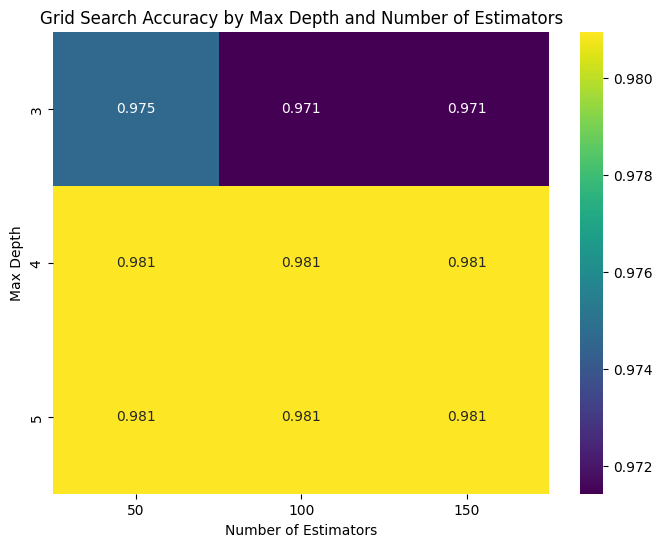

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Rata-rata akurasi CV untuk setiap pasangan (max_depth, n_estimators), dirata-ratakan atas learning rate
results = pd.DataFrame(grid_search.cv_results_)
pivot_table = results.pivot_table(values='mean_test_score',
                                  index='param_max_depth',
                                  columns='param_n_estimators')

plt.figure(figsize=(8,6))
sns.heatmap(pivot_table, annot=True, fmt='.3f', cmap='viridis')
plt.title('Grid Search Accuracy by Max Depth and Number of Estimators')
plt.xlabel('Number of Estimators')
plt.ylabel('Max Depth')
plt.show()

**Interpretasi output.** Karena setiap sel merata-ratakan ketiga *learning rate*:

* **Kedalaman 4 dan 5** menampilkan **0.981** di setiap sel: keenam kombinasi *learning rate* × kedalaman seri di posisi teratas untuk setiap jumlah pohon.
* **Kedalaman 3** sedikit lebih buruk: **0.975** dengan 50 pohon (rata-rata dari 0.9714, 0.9714, dan 0.9810) dan **0.971** dengan 100 atau 150 pohon.
* Skala warna hanya mencakup 0.971–0.981, selisih sekitar satu bunga per eksekusi CV, sehingga heatmap secara visual membesar-besarkan perbedaan yang sangat kecil.
* Bacaan praktisnya: kedalaman ≥ 4 sedikit lebih baik daripada kedalaman 3, dan jumlah pohon hampir tidak berpengaruh dalam rentang ini.

### Poin Penting
* Hiperparameter kunci *boosting* (`n_estimators`, `learning_rate`, `max_depth`) saling berinteraksi dan di-*tuning* bersama dengan CV.
* 20 dari 27 pengaturan seri di CV 0.981, sehingga yang dilaporkan sebagai terbaik hanyalah seri pertama, bukan model yang unik terbaik.
* `pivot_table` merata-ratakan parameter yang tidak diplot (di sini *learning rate*). Pahami apa yang diagregasi sebuah sel heatmap sebelum membacanya.

## Resep 8.5 — Membandingkan Metode Ensemble

**Tujuan.** Membandingkan tiga strategi ensemble (*bagging* dengan *random forest*, *boosting* dengan *gradient boosting*, dan *stacking* keduanya di bawah meta-model regresi logistik) pada pembagian Iris yang sama.

### Teori

**Intuisi.** *Bagging* merata-ratakan *learner* kuat yang independen (mengurangi variansi). *Boosting* merangkai *learner* lemah yang saling mengoreksi (mengurangi bias). **Stacking** mengambil model-model berbeda dan *mempelajari cara menggabungkannya*: sebuah meta-model melihat prediksi model-model dasar dan memutuskan seberapa besar mempercayai masing-masing untuk setiap kelas.

**Matematika.** Dengan model dasar $h_1,\dots,h_M$, *stacking* melatih meta-model $g$ pada prediksi **out-of-fold**. Data latih dibagi menjadi $K$ *fold*, setiap model dasar dilatih pada $K-1$ *fold* dan memprediksi *fold* yang disisihkan, sehingga diperoleh vektor fitur $\mathbf{z}_i=\big(h_1^{(-f(i))}(\mathbf{x}_i),\dots,h_M^{(-f(i))}(\mathbf{x}_i)\big)$ untuk setiap sampel latih $i$, dengan $f(i)$ adalah *fold* yang memuat $i$. Kemudian $g$ di-fit pada $\{(\mathbf{z}_i,y_i)\}$. Memakai prediksi *out-of-fold* mencegah meta-model belajar mempercayai model dasar yang sekadar menghafal data latih. Saat prediksi, model dasar (yang di-fit ulang pada semua data) menghasilkan $\mathbf{z}$ dan $\hat y=g(\mathbf{z})$. Dengan peluang kelas sebagai output, setiap model dasar menyumbang $K$ fitur, sehingga di sini $\mathbf{z}\in\mathbb{R}^{2\times3}=\mathbb{R}^6$.

**Cara scikit-learn mengimplementasikannya.** `StackingClassifier(estimators, final_estimator=None, cv=None, stack_method="auto", passthrough=False)`. `final_estimator=None` secara default menjadi `LogisticRegression()`. `cv=5` menghasilkan prediksi *out-of-fold*. `stack_method="auto"` memakai `predict_proba` jika tersedia, dan `passthrough=True` juga akan memasukkan fitur mentah ke meta-model. Setelah `fit`, `estimators_` adalah model dasar yang di-fit ulang pada semua data dan `final_estimator_` adalah meta-model hasil fit.

**Asumsi, kelebihan, keterbatasan.**

* *Stacking* paling membantu ketika model dasar **beragam** (pola kesalahan berbeda) dan data cukup banyak untuk mem-fit meta-model.
* Di sini kedua model dasar adalah ensemble pohon yang dilatih pada fitur yang sama dan membuat kesalahan yang sangat mirip, sehingga membatasi apa yang dapat diperoleh *stacking*.
* Biayanya $K+1$ kali fitting per model dasar, dan lebih sulit dijelaskan.

### Kode

In [18]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [19]:
# Bagging, boosting, dan stack keduanya yang digabung oleh regresi logistik
rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, random_state=2024)
stacking_clf = StackingClassifier(
    estimators=[('rf', rf_clf), ('gb', gb_clf)],
    final_estimator=LogisticRegression(),
    cv=5
)

rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)
stacking_clf.fit(X_train, y_train)

rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
stacking_pred = stacking_clf.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
stacking_accuracy = accuracy_score(y_test, stacking_pred)

print(f'Random Forest Accuracy: {rf_accuracy:.2f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}')
print(f'Stacking Accuracy: {stacking_accuracy:.2f}')

Random Forest Accuracy: 0.91
Gradient Boosting Accuracy: 0.87
Stacking Accuracy: 0.87


In [20]:
# Himpunan kesalahan dan bobot meta-model (tambahan)
for name, pred in [("random forest", rf_pred), ("gradient boosting", gb_pred), ("stacking", stacking_pred)]:
    print(f"{name:>17} salah pada: {np.flatnonzero(pred != y_test)}")
meta = stacking_clf.final_estimator_
cols = [f"{m}_P(class {k})" for m in ("rf", "gb") for k in range(3)]
pd.DataFrame(meta.coef_, index=[f"class {k}" for k in range(3)], columns=cols).round(2)

    random forest salah pada: [ 3 10 17 35]
gradient boosting salah pada: [ 3 10 17 26 35 38]
         stacking salah pada: [ 3 10 17 26 35 38]


,rf_P(class 0),rf_P(class 1),rf_P(class 2),gb_P(class 0),gb_P(class 1),gb_P(class 2)
class 0,1.36,-0.66,-0.70,1.38,-0.64,-0.74
class 1,-0.72,1.09,-0.37,-0.74,1.25,-0.51
class 2,-0.64,-0.42,1.07,-0.64,-0.60,1.25


**Interpretasi output.**

* **Random forest 0.91**, **gradient boosting 0.87**, dan **stacking 0.87**.
* Pengecekan tambahan menunjukkan bahwa *gradient boosting* dan *stacking* salah mengklasifikasikan **enam bunga yang sama** persis dengan pohon tunggal, sedangkan *random forest* hanya salah pada empat di antaranya.
* Tabel koefisien meta-model menjelaskan hasil *stacking*. Skor setiap kelas memberi bobot positif yang besar dan mirip pada peluang kelas itu dari *kedua* model dasar (misalnya kelas 0: 1,36 pada *forest*, 1,38 pada *boosting*). Meta-model pada dasarnya merata-ratakan dua pendapat yang sangat berkorelasi alih-alih mengutamakan *forest* yang lebih akurat. Prediksi *out-of-fold* yang dipakai untuk melatihnya hampir sempurna untuk kedua model dasar (akurasi CV ≈ 0,98 di Resep 8.4), sehingga ia tidak punya bukti bahwa salah satunya lebih baik.
* *Stacking* hanya menambah nilai ketika model dasar berbeda pendapat dengan cara yang berguna.

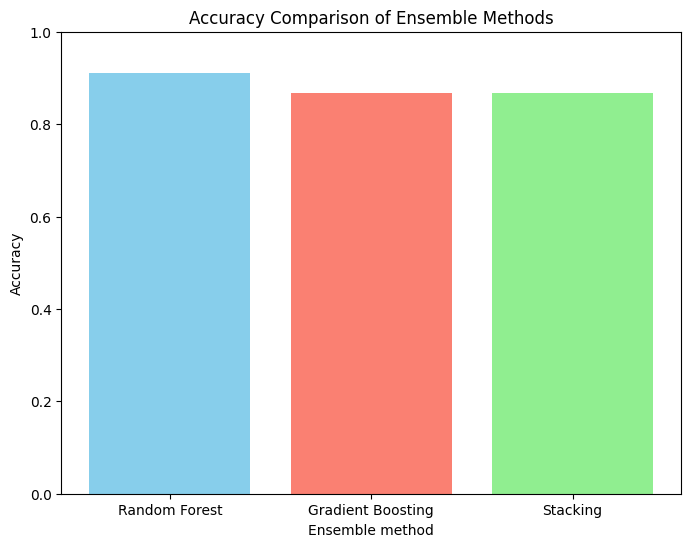

In [21]:
import matplotlib.pyplot as plt

# Akurasi uji ketiga ensemble berdampingan
methods = ['Random Forest', 'Gradient Boosting', 'Stacking']
accuracies = [rf_accuracy, gb_accuracy, stacking_accuracy]

plt.figure(figsize=(8, 6))
plt.bar(methods, accuracies, color=['skyblue', 'salmon', 'lightgreen'])
plt.title('Accuracy Comparison of Ensemble Methods')
plt.xlabel('Ensemble method')  # (tambahan)
plt.ylabel('Accuracy')
plt.ylim(0, 1)
plt.show()

> **Catatan:** Baris `plt.xlabel(...)` yang ditandai `# (tambahan)` tidak ada di buku. Baris ini hanya memberi label sumbu x.

**Interpretasi output.** Diagram batang menampilkan angka yang sama: *random forest* di 0.911 serta *gradient boosting* dan *stacking* di 0.867. Dengan sumbu y yang dimulai dari 0, selisih 4,4 poin (dua bunga dari 45) tampak kecil, gambaran yang jujur. Pada data uji 45 sampel, selisih dua prediksi adalah bukti yang lemah bahwa *bagging* secara umum lebih baik daripada *boosting* untuk masalah ini.

### Poin Penting
* *Bagging* (variansi ↓), *boosting* (bias ↓), dan *stacking* (kombinasi yang dipelajari) adalah strategi ensemble yang saling melengkapi.
* Pada Iris, *random forest* menang (0.91). *Boosting* dan *stacking* seri dengan pohon tunggal (0.87), dengan enam kesalahan yang sama.
* *Stacking* dua ensemble pohon yang mirip menghasilkan meta-model yang kira-kira merata-ratakan keduanya. Keragaman model dasar adalah yang membuat *stacking* bermanfaat.

## Resep 8.6 — Latihan Praktis Model Berbasis Pohon

**Tujuan.** Menerapkan model-model bab ini pada tiga dataset baru: (1) satu *decision tree* pada Wine, (2) *random forest* hasil *grid search* pada Breast Cancer, (3) *random forest* vs *gradient boosting* pada Digits.

### Teori

* **Latihan 1 (Wine, 13 fitur, 3 kultivar):** satu pohon yang tumbuh penuh, model bervariansi tinggi yang sama seperti Resep 8.1, kini pada dataset yang kelas-kelasnya dipisahkan oleh beberapa pengukuran kimia yang saling berkorelasi.
* **Latihan 2 (Breast Cancer, 30 fitur):** *random forest* yang di-*tuning* atas `n_estimators ∈ {50,100,150}`, `max_depth ∈ {3,5,7}`, dan `max_features ∈ {"sqrt","log2"}` (18 pengaturan × 5 *fold*). Membatasi `max_depth` menambah bias tetapi mengurangi variansi. `max_features` mengendalikan dekorelasi pohon: $\sqrt{30}\approx5$ vs $\log_2 30\approx4$ fitur per pemisahan. `error_score="raise"` membuat pencarian langsung gagal jika ada fitting yang error, alih-alih diam-diam memberinya skor NaN.
* **Latihan 3 (Digits, 64 fitur piksel, 10 kelas):** dengan banyak fitur yang masing-masing lemah informasinya, *bagging* dan *boosting* sama-sama unggul. *Gradient boosting* dengan 10 kelas mem-fit **10 pohon per iterasi** (1.000 pohon untuk 100 iterasi), sedangkan 100 pohon *forest* masing-masing langsung memprediksi ke-10 kelas.

### Kode — Latihan 1: Membangun dan Mengevaluasi Classifier Decision Tree

In [22]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report

wine = load_wine()
X = wine.data
y = wine.target

# Pembagian 70/30 -> 124 anggur latih / 54 anggur uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

clf = DecisionTreeClassifier(random_state=2024)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.78      0.88        18
           1       0.79      0.95      0.86        20
           2       0.94      0.94      0.94        16

    accuracy                           0.89        54
   macro avg       0.91      0.89      0.89        54
weighted avg       0.90      0.89      0.89        54



In [23]:
from sklearn.metrics import confusion_matrix

# Ukuran pohon dan letak kesalahannya (tambahan)
print(f"kedalaman = {clf.get_depth()}, daun = {clf.get_n_leaves()}, akurasi latih = {clf.score(X_train, y_train):.3f}")
print("confusion matrix (baris = kelas sebenarnya 0/1/2):\n", confusion_matrix(y_test, y_pred))

kedalaman = 4, daun = 7, akurasi latih = 1.000
confusion matrix (baris = kelas sebenarnya 0/1/2):
 [[14  4  0]
 [ 0 19  1]
 [ 0  1 15]]


**Interpretasi output.**

* Pohon mengklasifikasikan **89 %** dari 54 anggur uji dengan benar (48/54).
* Kelas 2 ditangani paling baik (F1 0.94). Kelas 0 memiliki *precision* sempurna (1.00) tetapi *recall* hanya 0.78.
* *Confusion matrix* menunjukkan kegagalan utamanya: **4 dari 18 anggur kelas 0 diprediksi sebagai kelas 1**, dan kelas 1 dan 2 tertukar masing-masing satu kali.
* Pohon kembali mem-fit data latihnya dengan sempurna (kedalaman 4, 7 daun). Pada dataset yang sama, PCA dan LDA di Bab 3 memisahkan kultivar hampir sempurna dengan memakai *kombinasi* fitur. Satu pohon yang sejajar sumbu, yang hanya melihat satu fitur pada satu waktu, tidak dapat memanfaatkan kombinasi itu seefisien itu.

### Kode — Latihan 2: Tuning Hiperparameter dengan Random Forest

In [24]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# 3 x 3 x 2 = 18 konfigurasi forest, masing-masing CV 5-fold
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 7],
    'max_features': ['sqrt', 'log2']
}
grid_search = GridSearchCV(RandomForestClassifier(random_state=2024), param_grid, cv=5, error_score='raise')
grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Best Parameters: {grid_search.best_params_}')
print(f'Accuracy: {accuracy:.2f}')

Best Parameters: {'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 150}
Accuracy: 0.95


In [25]:
# Puncak papan peringkat (tambahan)
lb = pd.DataFrame(grid_search.cv_results_)
lb["params"] = lb["params"].astype(str)
with pd.option_context("display.max_colwidth", None):
    display(lb[["params", "mean_test_score", "rank_test_score"]].sort_values("rank_test_score").head(6))

,params,mean_test_score,rank_test_score
10,"{'max_depth': 5, 'max_features': 'log2', 'n_estimators': 100}",0.954905,1
8,"{'max_depth': 5, 'max_features': 'sqrt', 'n_estimators': 150}",0.954905,1
17,"{'max_depth': 7, 'max_features': 'log2', 'n_estimators': 150}",0.954873,3
16,"{'max_depth': 7, 'max_features': 'log2', 'n_estimators': 100}",0.954842,4
11,"{'max_depth': 5, 'max_features': 'log2', 'n_estimators': 150}",0.952405,5
15,"{'max_depth': 7, 'max_features': 'log2', 'n_estimators': 50}",0.952373,6


**Interpretasi output.**

* *Forest* terbaik memakai **`max_depth=5, max_features='sqrt', n_estimators=150`** dan mencapai akurasi uji **95 %** (163/171). Angka itu sebanding dengan model regresi logistik dan SVM tanpa penskalaan pada pembagian ini di Bab 6–7 (0.94–0.95), dicapai tanpa penskalaan fitur sama sekali, tetapi di bawah regresi logistik L2 terstandardisasi di Resep 6.3 (0.982).
* Papan peringkat kembali menunjukkan seri di puncak. `max_depth=5, max_features='log2', n_estimators=100` memiliki skor CV yang identik (0.9549), dan pengaturan berikutnya (kedalaman 7) hanya berselisih 0,0001.
* Pohon dengan kedalaman terbatas (5, bukan tanpa batas) sedikit lebih baik dalam CV, petunjuk bahwa sedikit pengendalian variansi membantu pada dataset ini.

### Kode — Latihan 3: Membandingkan Gradient Boosting dan Random Forest

In [26]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score

digits = load_digits()
X = digits.data
y = digits.target

# Pembagian 70/30 -> 1.257 citra latih / 540 citra uji
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

rf_clf = RandomForestClassifier(n_estimators=100, random_state=2024)
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, random_state=2024)
rf_clf.fit(X_train, y_train)
gb_clf.fit(X_train, y_train)

rf_pred = rf_clf.predict(X_test)
gb_pred = gb_clf.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
gb_accuracy = accuracy_score(y_test, gb_pred)
print(f'Random Forest Accuracy: {rf_accuracy:.2f}')
print(f'Gradient Boosting Accuracy: {gb_accuracy:.2f}')

Random Forest Accuracy: 0.97
Gradient Boosting Accuracy: 0.96


In [27]:
# Akurasi tepat, jumlah kesalahan, dan ukuran model (tambahan)
print(f"random forest     : {rf_accuracy:.4f} ({int((rf_pred != y_test).sum())} kesalahan dari {len(y_test)}), pohon = {len(rf_clf.estimators_)}")
print(f"gradient boosting : {gb_accuracy:.4f} ({int((gb_pred != y_test).sum())} kesalahan dari {len(y_test)}), pohon = {gb_clf.estimators_.size}")

random forest     : 0.9685 (17 kesalahan dari 540), pohon = 100
gradient boosting : 0.9648 (19 kesalahan dari 540), pohon = 1000


**Interpretasi output.** Pada 540 digit uji, *random forest* mencapai **97 %** dan *gradient boosting* **96 %**. Sel tambahan memberi angka tepatnya: 0.9685 vs 0.9648, yaitu **17 vs 19 kesalahan**, selisih hanya dua citra. Kedua ensemble kuat pada masalah citra 64 dimensi dengan 10 kelas ini, sebanding dengan 97,5 % regresi logistik pada piksel terstandardisasi di Bab 3 (diukur pada pembagian 80/20 yang berbeda). *Forest* mencapainya dengan 100 pohon yang dilatih secara independen, sedangkan *boosting* membutuhkan 1.000 pohon yang dilatih berurutan (10 kelas × 100 iterasi) dengan pengaturan default yang belum di-*tuning*. Dengan *tuning* (lebih banyak iterasi, kedalaman, *learning rate*), *boosting* sering menyalip *forest*, tetapi tanpa *tuning* *forest* adalah pilihan yang lebih cepat dan sedikit lebih akurat di sini.

### Poin Penting
* Satu pohon pada Wine mencapai 89 %. Pohon mem-fit data latih dengan sempurna tetapi tidak dapat memanfaatkan kombinasi fitur sebaik proyeksi linear.
* *Random forest* berkedalaman terbatas hasil *tuning* mencapai 95 % pada data Breast Cancer tanpa penskalaan, dengan pengaturan teratas kembali seri.
* Pada Digits, *random forest* tanpa *tuning* (97 %) sedikit mengungguli *gradient boosting* tanpa *tuning* (96 %) dengan sepersepuluh jumlah pohon.

## Ringkasan Bab

| Resep | Konsep | Kelas/fungsi sklearn utama | Poin penting |
|---|---|---|---|
| 8.1 *Decision Tree* | Pemisahan CART rakus berdasarkan penurunan Gini | `DecisionTreeClassifier`, `plot_tree` | Latih 1.000 vs uji 0.867. Pemisahan terakhir bertumpu pada 4 bunga, gambaran *overfitting*. |
| 8.2 *Random Forest* | *Bootstrap* + subset fitur acak, peluang dirata-ratakan, MDI *importance* | `RandomForestClassifier` | 0.911, memperbaiki 2 dari 6 kesalahan pohon. Petal membawa sekitar 88 % *importance*. |
| 8.3 *Gradient Boosting* | Pohon berurutan yang di-fit pada pseudo-residual dengan *shrinkage* | `GradientBoostingClassifier` | *Loss* latih ≈ 1e-8 pada iterasi ke-100. Enam kesalahan yang sama dengan pohon tunggal (0.867). |
| 8.4 *Tuning* Hiperparameter | *Grid search* atas jumlah pohon × kedalaman × *learning rate* | `GridSearchCV`, heatmap `pivot_table` | 20/27 pengaturan seri di CV 0.981. Heatmap merata-ratakan atas *learning rate*. |
| 8.5 Membandingkan Ensemble | *Bagging* vs *boosting* vs *stacking* | `StackingClassifier` | RF 0.91 > GB = *stacking* 0.87. Model dasar yang mirip tidak memberi *stacking* apa pun untuk digabungkan. |
| 8.6 Latihan Praktis | Pohon dan ensemble pada Wine, Breast Cancer, Digits | pohon, RF hasil *tuning*, RF vs GB | 0.89 (pohon Wine), 0.95 (RF hasil *tuning*), 0.97 vs 0.96 (Digits RF vs GB). |

**Langkah selanjutnya.** Bab ini melengkapi perangkat inti *supervised learning* yang dibahas di repositori ini: pra-pemrosesan (Bab 2), reduksi dimensi (Bab 3), model berbasis jarak (Bab 4), linear (Bab 5–6), kernel (Bab 7), dan berbasis pohon (Bab 8). Buku berlanjut dengan pemrosesan teks dan strategi multikelas (Bab 9), *clustering* (Bab 10), deteksi pencilan (Bab 11), *cross-validation* dan evaluasi yang lebih ketat (Bab 12), serta *deployment* (Bab 13). Beberapa masalah yang ditemui di sini, seperti hasil *grid search* yang seri, skor CV yang optimis, dan data uji yang kecil, persis menjadi sasaran teknik evaluasi di Bab 12.

## Referensi

* Sukup, J. (2025). *scikit-learn Cookbook, Third Edition*. Packt Publishing. Bab 8.
* Repositori kode resmi: <https://github.com/PacktPublishing/Scikit-Learn-Cookbook-Third-Edition>
* scikit-learn User Guide — Decision Trees: <https://scikit-learn.org/1.5/modules/tree.html>
* scikit-learn User Guide — Ensembles: gradient boosting, random forests, bagging, voting, stacking: <https://scikit-learn.org/1.5/modules/ensemble.html>
* scikit-learn API — `StackingClassifier`: <https://scikit-learn.org/1.5/modules/generated/sklearn.ensemble.StackingClassifier.html>
* scikit-learn User Guide — Permutation feature importance: <https://scikit-learn.org/1.5/modules/permutation_importance.html>
* Breiman, L. (2001). Random Forests. *Machine Learning*, 45(1), 5–32.
* Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *Annals of Statistics*, 29(5), 1189–1232.